In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **SETUP**

In [2]:
import sys
import os
import torch
import cv2
import numpy as np
import PIL

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Pillow version:", PIL.__version__)

print("\nGPU Availability:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected")

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch version: 2.14.1+cu130
OpenCV version: 4.14.0
NumPy version: 2.4.6
Pillow version: 11.3.0

GPU Availability: True
GPU Name: Tesla T4


# **Dataset Path**

In [3]:
from pathlib import Path

DATASET_DIR = Path("/content/drive/MyDrive/COD10K-v3")

print("Dataset path:", DATASET_DIR)
print("Dataset exists:", DATASET_DIR.exists())

print("\nDataset contents:")

for item in sorted(DATASET_DIR.iterdir()):
    print(item.name)

Dataset path: /content/drive/MyDrive/COD10K-v3
Dataset exists: True

Dataset contents:
Info
Readme.txt
Test
Train


# **Verify**

In [5]:
for split in ["Train", "Test"]:

    image_dir = DATASET_DIR / split / "Image"
    mask_dir = DATASET_DIR / split / "GT_Object"

    print(f"\n===== {split} =====")

    print("Image folder exists:", image_dir.exists())
    print("Mask folder exists:", mask_dir.exists())

    if image_dir.exists() and mask_dir.exists():
        print("Images:", len(list(image_dir.glob("*"))))
        print("Masks:", len(list(mask_dir.glob("*"))))


===== Train =====
Image folder exists: True
Mask folder exists: True
Images: 6000
Masks: 6000

===== Test =====
Image folder exists: True
Mask folder exists: True
Images: 4000
Masks: 4000


# **IMAGE-MASK PAIR VERIFICATION**

In [6]:
for split in ["Train", "Test"]:

    image_dir = DATASET_DIR / split / "Image"
    mask_dir = DATASET_DIR / split / "GT_Object"

    # Get filenames without extensions
    image_names = {
        file.stem for file in image_dir.iterdir()
        if file.is_file()
    }

    mask_names = {
        file.stem for file in mask_dir.iterdir()
        if file.is_file()
    }

    # Compare image and mask filenames
    matched = image_names & mask_names
    missing_masks = image_names - mask_names
    missing_images = mask_names - image_names

    # Count CAM and NonCAM examples
    cam = sum("-CAM-" in name for name in image_names)
    noncam = sum("-NonCAM-" in name for name in image_names)

    print(f"\n========== {split} ==========")
    print("Images:", len(image_names))
    print("Masks:", len(mask_names))
    print("Matched pairs:", len(matched))
    print("Missing masks:", len(missing_masks))
    print("Missing images:", len(missing_images))
    print("CAM:", cam)
    print("NonCAM:", noncam)

    if missing_masks:
        print("Example missing masks:", list(missing_masks)[:5])

    if missing_images:
        print("Example missing images:", list(missing_images)[:5])


========== Train ==========
Images: 6000
Masks: 6000
Matched pairs: 6000
Missing masks: 0
Missing images: 0
CAM: 3040
NonCAM: 2960

========== Test ==========
Images: 4000
Masks: 4000
Matched pairs: 4000
Missing masks: 0
Missing images: 0
CAM: 2026
NonCAM: 1974


# **Image Dimension Analysis**

In [7]:
from PIL import Image
from collections import Counter
import random

random.seed(42)

for split in ["Train", "Test"]:

    image_dir = DATASET_DIR / split / "Image"

    image_paths = list(image_dir.glob("*"))
    sample_paths = random.sample(
        image_paths,
        min(100, len(image_paths))
    )

    dimensions = Counter()

    for path in sample_paths:
        with Image.open(path) as img:
            dimensions[img.size] += 1

    print(f"\n===== {split} =====")
    print("Images sampled:", len(sample_paths))
    print("Different dimensions:", len(dimensions))

    print("\nMost common dimensions:")

    for size, count in dimensions.most_common(10):
        print(f"{size}: {count} images")


===== Train =====
Images sampled: 100
Different dimensions: 67

Most common dimensions:
(800, 600): 8 images
(799, 533): 8 images
(1024, 683): 7 images
(1024, 768): 4 images
(533, 799): 2 images
(800, 571): 2 images
(534, 800): 2 images
(800, 533): 2 images
(1280, 960): 2 images
(682, 1024): 2 images

===== Test =====
Images sampled: 100
Different dimensions: 54

Most common dimensions:
(799, 533): 13 images
(800, 600): 11 images
(1024, 683): 7 images
(1024, 768): 5 images
(800, 533): 4 images
(768, 1024): 3 images
(800, 534): 3 images
(683, 1024): 3 images
(685, 1023): 2 images
(1023, 682): 2 images


# **Ground-Truth Mask Inspection**

In [8]:
import cv2
import numpy as np

mask_dir = DATASET_DIR / "Train" / "GT_Object"

cam_masks = sorted(mask_dir.glob("COD10K-CAM-*.png"))
noncam_masks = sorted(mask_dir.glob("COD10K-NonCAM-*.png"))

print("CAM masks available:", len(cam_masks))
print("NonCAM masks available:", len(noncam_masks))


def inspect_masks(mask_paths, category):

    print(f"\n===== {category} MASKS =====")

    for path in random.sample(mask_paths, min(3, len(mask_paths))):

        mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

        if mask is None:
            print("Could not read:", path.name)
            continue

        print({
            "name": path.name,
            "shape": mask.shape,
            "min": int(mask.min()),
            "max": int(mask.max()),
            "unique_values": np.unique(mask).tolist(),
            "foreground_pixels": int(np.count_nonzero(mask))
        })


inspect_masks(cam_masks, "CAM")
inspect_masks(noncam_masks, "NonCAM")

CAM masks available: 3040
NonCAM masks available: 2960

===== CAM MASKS =====
{'name': 'COD10K-CAM-1-Aquatic-16-Shrimp-1127.png', 'shape': (731, 1023), 'min': 0, 'max': 255, 'unique_values': [0, 255], 'foreground_pixels': 8680}
{'name': 'COD10K-CAM-3-Flying-62-Mantis-4282.png', 'shape': (768, 1024), 'min': 0, 'max': 255, 'unique_values': [0, 255], 'foreground_pixels': 75815}
{'name': 'COD10K-CAM-2-Terrestrial-34-Human-2026.png', 'shape': (1080, 1920), 'min': 0, 'max': 255, 'unique_values': [0, 255], 'foreground_pixels': 307319}

===== NonCAM MASKS =====
{'name': 'COD10K-NonCAM-5-Background-4-Sky-4363.png', 'shape': (533, 799), 'min': 0, 'max': 0, 'unique_values': [0], 'foreground_pixels': 0}
{'name': 'COD10K-NonCAM-5-Background-2-Ocean-3440.png', 'shape': (530, 800), 'min': 0, 'max': 0, 'unique_values': [0], 'foreground_pixels': 0}
{'name': 'COD10K-NonCAM-5-Background-4-Sky-4147.png', 'shape': (800, 1067), 'min': 0, 'max': 0, 'unique_values': [0], 'foreground_pixels': 0}


# **Image and Mask Dimension Consistency**
We verify that each original image and its corresponding ground-truth mask have identical dimensions. This is essential for accurate segmentation because every mask pixel must correspond to the correct image location.

In [9]:
from PIL import Image
import random

random.seed(42)

image_dir = DATASET_DIR / "Train" / "Image"
mask_dir = DATASET_DIR / "Train" / "GT_Object"

image_paths = list(image_dir.glob("*.jpg"))
sample_paths = random.sample(image_paths, 100)

matched_dimensions = 0
mismatched_dimensions = []

for image_path in sample_paths:

    mask_path = mask_dir / f"{image_path.stem}.png"

    with Image.open(image_path) as image:
        image_size = image.size

    with Image.open(mask_path) as mask:
        mask_size = mask.size

    if image_size == mask_size:
        matched_dimensions += 1
    else:
        mismatched_dimensions.append({
            "image": image_path.name,
            "image_size": image_size,
            "mask_size": mask_size
        })

print("Images checked:", len(sample_paths))
print("Matching dimensions:", matched_dimensions)
print("Mismatched dimensions:", len(mismatched_dimensions))

if mismatched_dimensions:
    print("\nExamples of mismatches:")
    for item in mismatched_dimensions[:5]:
        print(item)

Images checked: 100
Matching dimensions: 100
Mismatched dimensions: 0


In [10]:
# ==========================================
# 8. PROJECT DIRECTORY SETUP
# ==========================================

from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Camouflaged-Wildlife-Detection-System"
)

PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Directory exists:", PROJECT_DIR.exists())

Project directory: /content/drive/MyDrive/Camouflaged-Wildlife-Detection-System
Directory exists: True


# **dataset.py**

In [11]:
%%writefile /content/drive/MyDrive/Camouflaged-Wildlife-Detection-System/dataset.py

# ==========================================
# COD10K CUSTOM PYTORCH DATASET
# ==========================================

from pathlib import Path

import cv2
import numpy as np
import torch
from torch.utils.data import Dataset


class COD10KDataset(Dataset):

    def __init__(
        self,
        root_dir,
        split="Train",
        image_size=(352, 352)
    ):

        self.root_dir = Path(root_dir)
        self.split = split
        self.image_size = image_size

        # Define image and mask directories
        self.image_dir = self.root_dir / split / "Image"
        self.mask_dir = self.root_dir / split / "GT_Object"

        # Validate directories
        if not self.image_dir.exists():
            raise FileNotFoundError(self.image_dir)

        if not self.mask_dir.exists():
            raise FileNotFoundError(self.mask_dir)

        # Build image-mask pairs using filenames
        self.samples = []

        for image_path in sorted(self.image_dir.glob("*.jpg")):

            mask_path = self.mask_dir / f"{image_path.stem}.png"

            if mask_path.exists():
                self.samples.append((image_path, mask_path))

        if not self.samples:
            raise RuntimeError("No valid image-mask pairs found.")

    def __len__(self):

        return len(self.samples)

    def __getitem__(self, index):

        image_path, mask_path = self.samples[index]

        # Read image in BGR format
        image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)

        if image is None:
            raise RuntimeError(f"Cannot read image: {image_path}")

        # Convert BGR to RGB
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Read ground-truth mask in grayscale
        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

        if mask is None:
            raise RuntimeError(f"Cannot read mask: {mask_path}")

        # Resize image using bilinear interpolation
        image = cv2.resize(
            image,
            self.image_size,
            interpolation=cv2.INTER_LINEAR
        )

        # Resize mask using nearest-neighbor interpolation
        mask = cv2.resize(
            mask,
            self.image_size,
            interpolation=cv2.INTER_NEAREST
        )

        # Normalize pixel values to [0, 1]
        image = image.astype(np.float32) / 255.0
        mask = mask.astype(np.float32) / 255.0

        # Convert image from HWC to CHW
        image = np.transpose(image, (2, 0, 1))

        # Convert arrays into PyTorch tensors
        image = torch.from_numpy(image)
        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask

Writing /content/drive/MyDrive/Camouflaged-Wildlife-Detection-System/dataset.py


# **Load COD10k Dataset**

In [12]:
import sys

sys.path.insert(0, str(PROJECT_DIR))

from dataset import COD10KDataset

# Create training dataset
train_dataset = COD10KDataset(
    root_dir=DATASET_DIR,
    split="Train",
    image_size=(352, 352)
)

# Create testing dataset
test_dataset = COD10KDataset(
    root_dir=DATASET_DIR,
    split="Test",
    image_size=(352, 352)
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))
print("Total samples:", len(train_dataset) + len(test_dataset))

Training samples: 6000
Testing samples: 4000
Total samples: 10000


# **Inspecting Single Dataset Sample**

In [14]:
# ==========================================
# 10. INSPECT A SINGLE DATASET SAMPLE
# ==========================================

image, mask = train_dataset[0]

print("Image tensor:")
print("Shape:", image.shape)
print("Data type:", image.dtype)
print("Minimum:", image.min().item())
print("Maximum:", image.max().item())

print("\nMask tensor:")
print("Shape:", mask.shape)
print("Data type:", mask.dtype)
print("Minimum:", mask.min().item())
print("Maximum:", mask.max().item())

print("\nImage-mask sample loaded successfully!")

Image tensor:
Shape: torch.Size([3, 352, 352])
Data type: torch.float32
Minimum: 0.0
Maximum: 0.9686274528503418

Mask tensor:
Shape: torch.Size([1, 352, 352])
Data type: torch.float32
Minimum: 0.0
Maximum: 1.0

Image-mask sample loaded successfully!


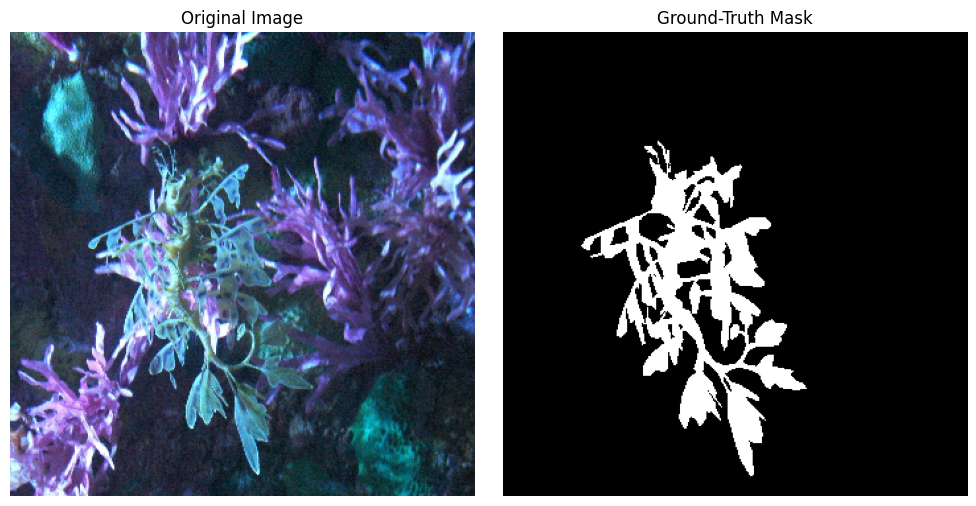

In [24]:
import matplotlib.pyplot as plt

# Load one sample
image, mask = train_dataset[8]

# Convert image from CHW to HWC for visualization
image = image.permute(1, 2, 0).numpy()

# Remove the mask channel
mask = mask.squeeze(0).numpy()

# Display image and mask side by side
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Ground-Truth Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

# **DataLoader**

In [25]:
from torch.utils.data import DataLoader

# Create training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0
)

# Create testing DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Training batches: 1500
Testing batches: 1000


In [26]:
# Get one batch from training data
images, masks = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)

print("Image data type:", images.dtype)
print("Mask data type:", masks.dtype)

Image batch shape: torch.Size([4, 3, 352, 352])
Mask batch shape: torch.Size([4, 1, 352, 352])
Image data type: torch.float32
Mask data type: torch.float32


# **visualize_dataset.py**

In [41]:

%%writefile /content/drive/MyDrive/Camouflaged-Wildlife-Detection-System/scripts/visualize_dataset.py

import argparse
import sys
from pathlib import Path

import matplotlib.pyplot as plt

# Automatically locate the project directory
PROJECT_DIR = Path(__file__).resolve().parent.parent

# Allow importing dataset.py from the project root
sys.path.insert(0, str(PROJECT_DIR))

from dataset import COD10KDataset


def visualize_sample(dataset_dir, split="Train", index=0):

    # Resolve the dataset directory supplied by the user
    dataset_dir = Path(dataset_dir).expanduser().resolve()

    if not dataset_dir.exists():
        raise FileNotFoundError(
            f"Dataset directory not found: {dataset_dir}"
        )

    dataset = COD10KDataset(
        root_dir=dataset_dir,
        split=split,
        image_size=(352, 352)
    )

    if index < 0 or index >= len(dataset):
        raise IndexError(
            f"Index must be between 0 and {len(dataset) - 1}"
        )

    image, mask = dataset[index]

    image = image.permute(1, 2, 0).numpy()
    mask = mask.squeeze(0).numpy()

    # Create side-by-side visualization
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(image)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(mask, cmap="gray")
    plt.title("Ground-Truth Mask")
    plt.axis("off")

    plt.tight_layout()

    # Automatically save inside the project's results folder
    output_dir = PROJECT_DIR / "results"
    output_dir.mkdir(parents=True, exist_ok=True)

    output_path = output_dir / f"{split.lower()}_sample_{index}.png"

    plt.savefig(output_path, dpi=150, bbox_inches="tight")
    plt.close()

    print("Visualization completed successfully!")
    print(f"Dataset: {dataset_dir}")
    print(f"Split: {split}")
    print(f"Sample index: {index}")
    print(f"Output saved to: {output_path}")


if __name__ == "__main__":

    parser = argparse.ArgumentParser(
        description="Visualize a COD10K image and its ground-truth mask."
    )

    parser.add_argument(
        "--dataset_dir",
        type=str,
        required=True,
        help="Path to the extracted COD10K-v3 dataset directory."
    )

    parser.add_argument(
        "--split",
        type=str,
        default="Train",
        choices=["Train", "Test"]
    )

    parser.add_argument(
        "--index",
        type=int,
        default=0
    )

    args = parser.parse_args()

    visualize_sample(
        dataset_dir=args.dataset_dir,
        split=args.split,
        index=args.index
    )

Overwriting /content/drive/MyDrive/Camouflaged-Wildlife-Detection-System/scripts/visualize_dataset.py


In [43]:
!python "/content/drive/MyDrive/Camouflaged-Wildlife-Detection-System/scripts/visualize_dataset.py" \
    --dataset_dir "/content/drive/MyDrive/COD10K-v3" \
    --split Train \
    --index 2

Visualization completed successfully!
Dataset: /content/drive/MyDrive/COD10K-v3
Split: Train
Sample index: 2
Output saved to: /content/drive/MyDrive/Camouflaged-Wildlife-Detection-System/results/train_sample_2.png


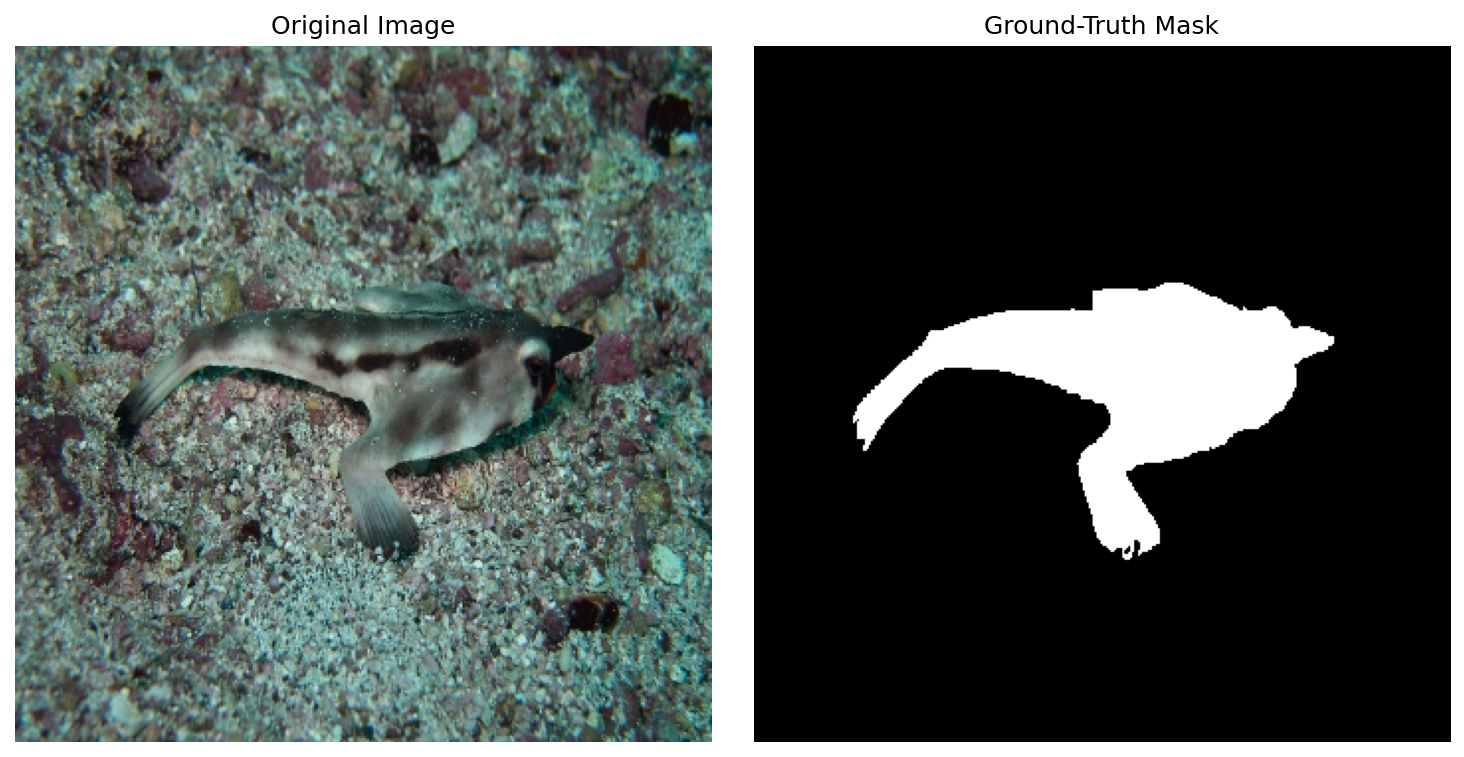

In [45]:
from IPython.display import display, Image
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Camouflaged-Wildlife-Detection-System"
)

output_image = PROJECT_DIR / "results" / "train_sample_0.png"

display(Image(filename=str(output_image)))

In [58]:
import subprocess
from getpass import getpass

PROJECT_DIR = "/content/drive/MyDrive/Camouflaged-Wildlife-Detection-System"

github_username = "ArhamMahmood"
github_token = getpass("Enter your GitHub token (input hidden): ")

# Keep credentials in temporary memory for one hour
subprocess.run(
    ["git", "config", "--global", "credential.helper",
     "cache --timeout=3600"],
    check=True
)

# Supply credentials privately to Git
credential = (
    f"protocol=https\n"
    f"host=github.com\n"
    f"username={github_username}\n"
    f"password={github_token}\n\n"
)

subprocess.run(
    ["git", "credential", "approve"],
    input=credential,
    text=True,
    check=True
)

github_token = None
credential = None

print("GitHub authentication configured.")

Enter your GitHub token (input hidden): ··········
GitHub authentication configured.


In [59]:
import subprocess

PROJECT_DIR = "/content/drive/MyDrive/Camouflaged-Wildlife-Detection-System"

result = subprocess.run(
    ["git", "push", "-u", "origin", "main"],
    cwd=PROJECT_DIR,
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

if result.returncode == 0:
    print("Successfully pushed to GitHub!")
else:
    print("Push failed. Share the error output, but never share your token.")

branch 'main' set up to track 'origin/main'.

To https://github.com/ArhamMahmood/Camouflaged-Wildlife-Detection-System.git
 * [new branch]      main -> main

Successfully pushed to GitHub!
